# **Preparación de datos — Modelo IA de Predicción de Abandono (CHURN) v2**

Este notebook prepara los datos con los que se entrena el modelo en `TrainModel.ipynb`.

**Cambio principal frente al modelo v1:** la etiqueta de abandono ya **no** viene dada en el dataset. Se construye con una **fecha de corte**:

```
|----- ventana de observación (365 días) -----| CORTE |----- ventana de predicción (90 días) -----|
      variables: solo compras ANTES del corte              churn = 1 si NO compra en esta ventana
```

Así el modelo aprende a **anticipar** el abandono con información del pasado, en lugar de redescubrir la regla con la que se construyó la etiqueta (fuga de datos del v1).

**Pasos del notebook**
1. Configuración y carga de Online Retail II (dataset principal)
2. Limpieza
3. Análisis del tiempo entre compras → justificación de la ventana de 90 días
4. Variables del modelo (`features.py`)
5. Cortes temporales y construcción de los conjuntos train / validación / test
6. Verificación automática de ausencia de fuga de datos
7. Dataset de validación externa (CDNOW)
8. Auditoría del dataset del modelo v1
9. Exportación de los datos preparados a la carpeta `Data/`

> Ejecutar las celdas en orden. Al terminar, ejecutar `TrainModel.ipynb`.

## **1. Configuración y carga de datos**
**Datasets** (carpeta `app/ia/datasets`):

| Archivo | Uso | Fuente |
|---|---|---|
| `online_retail_ii.csv.gz` | Entrenamiento, validación y test | UCI Online Retail II, CC BY 4.0 (https://archive.ics.uci.edu/dataset/502) |
| `CDNOW_master.txt` | Validación externa (otro negocio) | Fader & Hardie, 2001 |
| `Customers_Data.csv`, `Customer_Activity_Data.csv` | Solo auditoría del modelo v1 | Dataset original de la tesis |

> Si falta `online_retail_ii.csv.gz`, descargue `online_retail_II.xlsx` de la UCI y ejecute la celda opcional de conversión que está más abajo.

In [2]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 1.6 MB/s eta 0:00:06
   ---- ----------------------------------- 1.0/9.3 MB 1.7 MB/s eta 0:00:05
   ----- ---------------------------------- 1.3/9.3 MB 1.8 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.3 MB 1.9 MB/s eta 0:00:05
   ---------- ----------------------------- 2.4/9.3 MB 1.9 MB/s eta 0:00:04
   ----------- ---------------------------- 2.6/9.3 MB 1.9 MB/s eta 0:00:04
   ------------ --------------------------- 2.9/9.3 MB 1.9 MB/s eta 0:00:04
   ------------- -------------------------- 3.1/9.3 MB 1.8 MB/s eta 0:00:04
   --------------- ------------------------ 3.7/9.3 MB 1.8 MB/s eta 0:00:04
   ---------------- ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Sr. Sebastian\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Variables del modelo: el MISMO archivo lo usa la API (no copiar estas fórmulas en otro lugar)
from features import FEATURES, construir_features, construir_snapshot, _a_compras

DATASETS = Path("../datasets")     # app/ia/datasets
SALIDA = Path("Data")              # datos preparados para TrainModel.ipynb
SALIDA.mkdir(exist_ok=True)

VENTANA_PREDICCION = 90            # días: ¿vuelve a comprar en este periodo?
VENTANA_OBSERVACION = 365          # días de historia usados para calcular las variables
VENTANAS_SENSIBILIDAD = [60, 90, 120]

In [4]:
# (OPCIONAL) Convertir la descarga oficial de la UCI a CSV comprimido. Solo si el archivo no existe.
archivo_orii = DATASETS / "online_retail_ii.csv.gz"
if not archivo_orii.exists():
    hojas = pd.read_excel(DATASETS / "online_retail_II.xlsx", sheet_name=None,
                          dtype={"Invoice": str, "StockCode": str})          # requiere openpyxl
    crudo = pd.concat(hojas.values(), ignore_index=True).rename(columns={"Customer ID": "CustomerID"})
    crudo.to_csv(archivo_orii, index=False, compression="gzip")
print("Archivo disponible:", archivo_orii.exists())

Archivo disponible: True


In [5]:
orii = pd.read_csv(DATASETS / "online_retail_ii.csv.gz",
                   dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])
print("Filas:", len(orii))
print("Periodo:", orii["InvoiceDate"].min(), "->", orii["InvoiceDate"].max())
orii.head()

Filas: 1067371
Periodo: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12.0,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12.0,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12.0,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48.0,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24.0,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## **2. Limpieza**
- Se eliminan filas sin `CustomerID` (no se puede seguir al cliente).
- Se eliminan facturas de cancelación (`Invoice` que empieza con **C**), cantidades ≤ 0 y precios ≤ 0.
- Solo **Reino Unido**: un único mercado homogéneo, análogo a un comercio local.

Al final se deja el **contrato de transacciones** que usa todo el proyecto (también la API):
`cliente_id, factura_id, fecha, monto, tienda_id`

In [6]:
pasos = {"inicial": len(orii)}
df = orii.dropna(subset=["CustomerID"]);                  pasos["sin cliente nulo"] = len(df)
df = df[~df["Invoice"].str.startswith("C")];              pasos["sin cancelaciones"] = len(df)
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)];       pasos["cantidad y precio > 0"] = len(df)
df = df[df["Country"] == "United Kingdom"];               pasos["solo Reino Unido"] = len(df)

trans = pd.DataFrame({
    "cliente_id": df["CustomerID"].astype(int).astype(str),
    "factura_id": df["Invoice"].astype(str),
    "fecha": df["InvoiceDate"],
    "monto": df["Quantity"] * df["Price"],
    "tienda_id": "online_retail_ii",
}).sort_values("fecha").reset_index(drop=True)

display(pd.Series(pasos, name="filas"))
print(f"Clientes: {trans.cliente_id.nunique()}  |  Facturas: {trans.factura_id.nunique()}")

inicial                  1067371
sin cliente nulo          824364
sin cancelaciones         805620
cantidad y precio > 0     805549
solo Reino Unido          725250
Name: filas, dtype: int64

Clientes: 5350  |  Facturas: 33541


## **3. Tiempo entre compras: ¿qué ventana de predicción usar?**
La ventana debe ser más larga que el ritmo normal de recompra. Si un cliente suele comprar cada mes, 90 días sin comprar ya es una señal de abandono.

Días entre compras  P25=7  P50=25  P75=62  P90=137


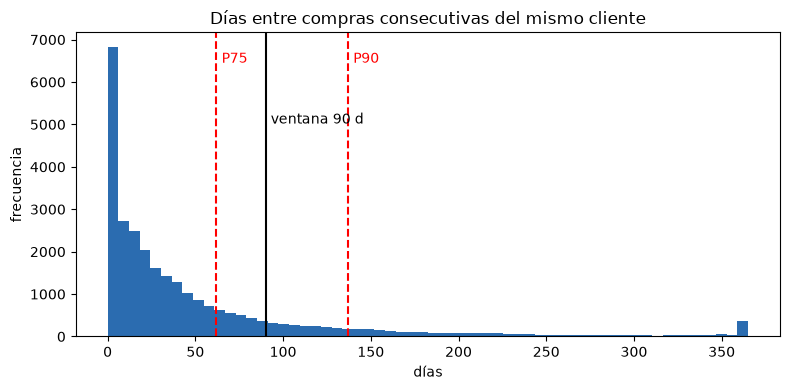

In [7]:
compras = _a_compras(trans).sort_values(["cliente_id", "fecha"])
intervalos = compras.groupby("cliente_id")["fecha"].diff().dt.days.dropna()
percentiles = np.percentile(intervalos, [25, 50, 75, 90])
print("Días entre compras  P25={:.0f}  P50={:.0f}  P75={:.0f}  P90={:.0f}".format(*percentiles))

plt.figure(figsize=(8, 4))
plt.hist(intervalos.clip(upper=365), bins=60, color="#2b6cb0")
for p, et in zip(percentiles[2:], ["P75", "P90"]):
    plt.axvline(p, color="red", ls="--"); plt.text(p + 3, plt.ylim()[1] * 0.9, et, color="red")
plt.axvline(VENTANA_PREDICCION, color="black"); plt.text(VENTANA_PREDICCION + 3, plt.ylim()[1] * 0.7, "ventana 90 d")
plt.title("Días entre compras consecutivas del mismo cliente"); plt.xlabel("días"); plt.ylabel("frecuencia")
plt.tight_layout(); plt.show()

**Interpretación:** el 75 % de las recompras ocurre antes de ~62 días y el 90 % antes de ~137 días. Una ventana de **90 días** queda entre ambos valores: no marca como abandono a un cliente que simplemente está en su ritmo normal, y aún permite actuar a tiempo. En `TrainModel.ipynb` se hace además un análisis de sensibilidad con 60 y 120 días.

## **4. Variables del modelo**
Las variables se calculan con `construir_features(transacciones, fecha_referencia)` del archivo `features.py`. **La misma función la usa la API** al predecir, lo que garantiza que el modelo recibe en producción exactamente lo mismo que vio al entrenar.

| Variable | Significado |
|---|---|
| `recencia_dias` | Días desde la última compra |
| `frecuencia` | Nº de compras en los últimos 365 días |
| `antiguedad_dias` | Días desde la primera compra (dentro de la ventana) |
| `compras_por_mes` | Frecuencia / meses de antigüedad |
| `compras_30d`, `compras_90d` | Compras en los últimos 30 y 90 días |
| `tendencia_90d` | Compras de los últimos 90 días − compras de los 90 anteriores |
| `intercompra_media` | Días promedio entre compras (365 si solo hay una compra) |
| `intercompra_cv` | Irregularidad del ritmo de compra (desviación / media) |
| `ratio_recencia` | Recencia / intercompra media → "lleva X veces su ritmo habitual sin comprar" |
| `compra_unica` | 1 si solo compró una vez en el año |
| `log_ticket_relativo` | Ticket medio del cliente frente al ticket típico **de su tienda** (log) |
| `log_monetario_relativo` | Gasto anual frente al cliente típico **de su tienda** (log) |

> Los montos son **relativos a la tienda**: el modelo funciona igual con libras, dólares o pesos colombianos.

In [8]:
# Ejemplo: variables de 3 clientes al 1 de junio de 2011
ejemplo = construir_features(trans, "2011-06-01", VENTANA_OBSERVACION)
ejemplo[FEATURES].head(3).round(2)

,recencia_dias,frecuencia,antiguedad_dias,compras_por_mes,compras_30d,compras_90d,tendencia_90d,intercompra_media,intercompra_cv,ratio_recencia,compra_unica,log_ticket_relativo,log_monetario_relativo
cliente_id,,,,,,,,,,,,,
12346,133.58,2.0,337.42,0.18,0.0,0.0,-1.0,203.84,0.0,0.66,0.0,4.85,4.80
12608,212.55,1.0,212.55,0.14,0.0,0.0,0.0,365.00,0.0,0.58,1.0,0.32,-0.43
12745,294.57,1.0,294.57,0.10,0.0,0.0,0.0,365.00,0.0,0.81,1.0,-0.12,-0.87


## **5. Cortes temporales y conjuntos de datos**
Se toma una "foto" de los clientes **el primer día de cada mes** (corte). Para cada foto se calculan las variables con el pasado y la etiqueta con los 90 días siguientes.

El reparto es **temporal**, no aleatorio, para simular el uso real (entrenar con el pasado, predecir el futuro):
- **Entrenamiento:** cortes antiguos, cuyas etiquetas terminan antes del corte de validación.
- **Validación:** un corte, usado para calibrar las probabilidades y elegir el modelo.
- **Test:** el último corte con 90 días de futuro observado. Solo se usa para reportar resultados.

In [9]:
def calcular_cortes(trans, ventana, obs_dias):
    # Cortes mensuales sin solapamiento de etiquetas entre train, validación y test
    mes = lambda ts: pd.Timestamp(ts).to_period("M").to_timestamp()
    inicio, fin = trans["fecha"].min(), trans["fecha"].max()
    test = mes(fin - pd.Timedelta(days=ventana))
    valid = mes(test - pd.Timedelta(days=ventana))
    ultimo_train = mes(valid - pd.Timedelta(days=ventana))
    primero = mes(inicio + pd.Timedelta(days=obs_dias + 27))
    return {"train": list(pd.date_range(primero, ultimo_train, freq="MS")),
            "valid": [valid], "test": [test]}


def construir_conjuntos(trans, ventana, obs_dias):
    cortes = calcular_cortes(trans, ventana, obs_dias)
    partes = []
    for conjunto, lista in cortes.items():
        for corte in lista:
            s = construir_snapshot(trans, corte, ventana, obs_dias)
            s["conjunto"] = conjunto
            partes.append(s)
    return pd.concat(partes, ignore_index=True), cortes


conjuntos, cortes = construir_conjuntos(trans, VENTANA_PREDICCION, VENTANA_OBSERVACION)
for k, v in cortes.items():
    print(f"{k:6s}: {[str(c.date()) for c in v]}")

resumen = conjuntos.groupby("conjunto").agg(filas=("churn", "size"), clientes=("cliente_id", "nunique"),
                                            pct_abandono=("churn", "mean")).loc[["train", "valid", "test"]]
resumen.round(3)

train : ['2010-12-01', '2011-01-01', '2011-02-01', '2011-03-01']
valid : ['2011-06-01']
test  : ['2011-09-01']


,filas,clientes,pct_abandono
conjunto,,,
train,15631,4164,0.661
valid,3969,3969,0.639
test,3947,3947,0.508


**Nota sobre la estacionalidad:** el corte de test (septiembre → noviembre) incluye la temporada navideña, cuando más clientes vuelven a comprar. Por eso tiene menos abandono (~51 %) que los cortes de entrenamiento (~66 %). Esto afecta la **calibración** de las probabilidades y se analiza en `TrainModel.ipynb`.

## **6. Verificación de ausencia de fuga de datos**
Comprobaciones automáticas. Si alguna falla, la celda se detiene con un error:
1. Toda variable se calculó con compras **anteriores** al corte (recencia > 0).
2. La antigüedad nunca supera la ventana de observación.
3. La etiqueta se puede reconstruir usando **solo** compras posteriores al corte.
4. Las etiquetas de train terminan antes del corte de validación, y las de validación antes del de test.
5. Las variables de un corte **no cambian** si se agregan compras futuras.

In [10]:
for corte, grupo in conjuntos.groupby("fecha_corte"):
    assert (grupo["recencia_dias"] > 0).all(), f"recencia <= 0 en {corte}"
    assert (grupo["antiguedad_dias"] <= VENTANA_OBSERVACION + 1).all(), "antigüedad fuera de ventana"
    futuras = trans[(trans.fecha >= corte) & (trans.fecha < corte + pd.Timedelta(days=VENTANA_PREDICCION))]
    esperado = (~grupo["cliente_id"].isin(futuras["cliente_id"].unique())).astype(int)
    assert (esperado.values == grupo["churn"].values).all(), f"etiqueta inconsistente en {corte}"

fin_train = max(cortes["train"]) + pd.Timedelta(days=VENTANA_PREDICCION)
fin_valid = cortes["valid"][0] + pd.Timedelta(days=VENTANA_PREDICCION)
assert fin_train <= cortes["valid"][0], "las etiquetas de train invaden validación"
assert fin_valid <= cortes["test"][0], "las etiquetas de validación invaden test"

c = cortes["valid"][0]
solo_pasado = construir_features(trans[trans.fecha < c], c)
assert solo_pasado.equals(construir_features(trans, c)), "las variables dependen del futuro"

print("✔ Sin fuga de datos en", conjuntos["fecha_corte"].nunique(), "cortes")
print(f"✔ Etiquetas de train terminan {fin_train.date()} <= corte de validación {cortes['valid'][0].date()}")
print(f"✔ Etiquetas de validación terminan {fin_valid.date()} <= corte de test {cortes['test'][0].date()}")

✔ Sin fuga de datos en 6 cortes
✔ Etiquetas de train terminan 2011-05-30 <= corte de validación 2011-06-01
✔ Etiquetas de validación terminan 2011-08-30 <= corte de test 2011-09-01


### Conjuntos para el análisis de sensibilidad (60 y 120 días)

In [11]:
sensibilidad = {}
for v in VENTANAS_SENSIBILIDAD:
    if v == VENTANA_PREDICCION:
        continue
    sensibilidad[v], _ = construir_conjuntos(trans, v, VENTANA_OBSERVACION)
    abandono_test = sensibilidad[v].loc[sensibilidad[v]["conjunto"] == "test", "churn"].mean()
    print(f"ventana {v:3d} días -> filas={len(sensibilidad[v])}, % abandono en test={abandono_test:.3f}")

ventana  60 días -> filas=35485, % abandono en test=0.573
ventana 120 días -> filas=11866, % abandono en test=0.481


## **7. Dataset de validación externa: CDNOW**
CDNOW es una tienda de discos de EE. UU. (1997–1998): **otro negocio, otra moneda y otra época**. Se usa para comprobar si lo aprendido se transfiere, igual que se espera al llevar el modelo a una MiPyME de Santander de Quilichao.
- Corte de **recalibración**: 1998-01-01 (simula los "datos locales" de la tienda).
- Corte de **prueba**: 1998-04-01.

In [12]:
cd = pd.read_csv(DATASETS / "CDNOW_master.txt", sep=r"\s+", header=None,
                 names=["id", "fecha", "cds", "valor"], dtype={"id": str, "fecha": str})
cd = cd[cd["valor"] > 0]
trans_cdnow = pd.DataFrame({
    "cliente_id": cd["id"],
    "factura_id": cd["id"] + "_" + cd["fecha"],     # una compra = cliente + día
    "fecha": pd.to_datetime(cd["fecha"], format="%Y%m%d"),
    "monto": cd["valor"],
    "tienda_id": "cdnow",
})
print(f"CDNOW: {len(trans_cdnow)} transacciones, {trans_cdnow.cliente_id.nunique()} clientes, "
      f"{trans_cdnow.fecha.min().date()} -> {trans_cdnow.fecha.max().date()}")

cdnow_cal = construir_snapshot(trans_cdnow, "1998-01-01", VENTANA_PREDICCION, VENTANA_OBSERVACION)
cdnow_test = construir_snapshot(trans_cdnow, "1998-04-01", VENTANA_PREDICCION, VENTANA_OBSERVACION)
print(f"recalibración: {len(cdnow_cal)} clientes, abandono {cdnow_cal.churn.mean():.3f}")
print(f"prueba:        {len(cdnow_test)} clientes, abandono {cdnow_test.churn.mean():.3f}")

CDNOW: 69579 transacciones, 23502 clientes, 1997-01-01 -> 1998-06-30
recalibración: 23502 clientes, abandono 0.838
prueba:        9526 clientes, abandono 0.702


## **8. Auditoría del dataset del modelo v1**
Evidencia de por qué el modelo v1 obtenía 100 % de precisión. Este resultado se usa en el capítulo de resultados de la tesis.

In [13]:
from sklearn.metrics import roc_auc_score

clientes_v1 = pd.read_csv(DATASETS / "Customers_Data.csv", parse_dates=["registration_date", "last_purchase_date"])
actividad_v1 = pd.read_csv(DATASETS / "Customer_Activity_Data.csv", parse_dates=["activity_date"])

fecha_dataset = clientes_v1["last_purchase_date"].max()
recencia_v1 = (fecha_dataset - clientes_v1["last_purchase_date"]).dt.days
y_v1 = clientes_v1["churn_status"]

compras_v1 = actividad_v1[actividad_v1["activity_type_id"] == 2]
ultima_evento = compras_v1.groupby("customer_id")["activity_date"].max().reindex(clientes_v1["id"])
n_eventos = compras_v1.groupby("customer_id").size().reindex(clientes_v1["id"]).fillna(0)

auditoria = {
    "n_clientes": int(len(clientes_v1)),
    "prevalencia_churn": round(float(y_v1.mean()), 4),
    "auc_usando_solo_recencia": round(float(roc_auc_score(y_v1, recencia_v1)), 4),
    "coincidencia_etiqueta_con_regla": {f">{d}_dias_sin_comprar": round(float(((recencia_v1 > d).astype(int) == y_v1).mean()), 4)
                                        for d in (60, 90, 120, 180)},
    "corr_eventos_compra_vs_total_purchases": round(float(np.corrcoef(n_eventos, clientes_v1["total_purchases"])[0, 1]), 4),
    "pct_clientes_con_compras_despues_de_last_purchase_date":
        round(float(np.nanmean(ultima_evento.values > clientes_v1["last_purchase_date"].values)), 4),
    "v1_reportado": {"accuracy": 1.0, "matriz_confusion": [[18, 0], [0, 92]]},
}
print(json.dumps(auditoria, indent=2, ensure_ascii=False))

{
  "n_clientes": 550,
  "prevalencia_churn": 0.8345,
  "auc_usando_solo_recencia": 1.0,
  "coincidencia_etiqueta_con_regla": {
    ">60_dias_sin_comprar": 0.9436,
    ">90_dias_sin_comprar": 0.9982,
    ">120_dias_sin_comprar": 0.9709,
    ">180_dias_sin_comprar": 0.9364
  },
  "corr_eventos_compra_vs_total_purchases": 0.1124,
  "pct_clientes_con_compras_despues_de_last_purchase_date": 0.8255,
  "v1_reportado": {
    "accuracy": 1.0,
    "matriz_confusion": [
      [
        18,
        0
      ],
      [
        0,
        92
      ]
    ]
  }
}


**Conclusión:** la etiqueta `churn_status` coincide en un 99,8 % con la regla "más de 90 días sin comprar", y la recencia por sí sola separa perfectamente las clases (AUC = 1,0). Además, el registro de actividad no corresponde con las compras declaradas. El modelo v1 **no predecía**: reproducía la regla con la que se construyó la etiqueta. Este dataset no se usa para entrenar el modelo v2.

## **9. Exportar los datos preparados**
Archivos generados en `Data/`, que son la entrada de `TrainModel.ipynb`.

In [14]:
conjuntos.to_csv(SALIDA / f"churn_conjuntos_v{VENTANA_PREDICCION}.csv", index=False)
for v, df_v in sensibilidad.items():
    df_v.to_csv(SALIDA / f"churn_conjuntos_v{v}.csv", index=False)
cdnow_cal.to_csv(SALIDA / "cdnow_recalibracion.csv", index=False)
cdnow_test.to_csv(SALIDA / "cdnow_test.csv", index=False)

info = {
    "ventana_prediccion_dias": VENTANA_PREDICCION,
    "ventana_observacion_dias": VENTANA_OBSERVACION,
    "definicion_etiqueta": (f"churn = 1 si el cliente, con >=1 compra en los {VENTANA_OBSERVACION} días previos al "
                            f"corte, NO compra en los {VENTANA_PREDICCION} días siguientes al corte"),
    "cortes": {k: [str(c.date()) for c in v] for k, v in cortes.items()},
    "limpieza_online_retail_ii": pasos,
    "intercompra_percentiles_25_50_75_90": [float(p) for p in percentiles],
    "auditoria_v1": auditoria,
}
(SALIDA / "info_preparacion.json").write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding="utf-8")
print("Datos preparados exportados a 'Data/':")
for f in sorted(SALIDA.iterdir()):
    print(f"  {f.name:32s} {f.stat().st_size / 1e6:6.2f} MB")

Datos preparados exportados a 'Data/':
  cdnow_recalibracion.csv            3.51 MB
  cdnow_test.csv                     1.44 MB
  churn_conjuntos_v120.csv           2.37 MB
  churn_conjuntos_v60.csv            7.09 MB
  churn_conjuntos_v90.csv            4.71 MB
  info_preparacion.json              0.00 MB
